# Movie Data Analysis
### Exploratory Data Analysis with Python, Pandas, Matplotlib & Seaborn

**Portfolio project** focused on data cleaning, feature engineering, exploratory analysis, and visualization of a movie dataset.

> **Dataset:** `mymoviedb.csv`  
> **Tools:** Python • Pandas • NumPy • Matplotlib • Seaborn

---

### Objectives
- Inspect and understand the dataset structure
- Clean and transform movie metadata
- Categorize movies using vote averages
- Analyze genre distribution and popularity
- Identify highly and least popular movies
- Explore movie releases across years

### Notebook Roadmap
1. Data Loading & Initial Inspection
2. Data Cleaning & Transformation
3. Feature Engineering
4. Exploratory Data Analysis
5. Key Findings
6. Conclusion


## 1. Data Loading & Initial Inspection

We begin by loading the movie dataset and reviewing its structure, sample records, missing values, duplicates, and descriptive statistics.

In [1]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings for cleaner notebook output
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Plot style
sns.set_theme(style="whitegrid", context="notebook")

In [2]:
# Load the dataset
# Keep `mymoviedb.csv` in the same folder as this notebook.
df = pd.read_csv("mymoviedb.csv", lineterminator="\n")

print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")

Dataset shape: 9,827 rows × 9 columns


### Sample Records

In [3]:
df.head()

,Release_Date,Title,Overview,Popularity,Vote_Count,Vote_Average,Original_Language,Genre,Poster_Url
0,2021-12-15,Spider-Man: No Way Home,Peter Parker is unmasked and no longer able to...,"5,083.95",8940,8.30,en,"Action, Adventure, Science Fiction",https://image.tmdb.org/t/p/original/1g0dhYtq4i...
1,2022-03-01,The Batman,"In his second year of fighting crime, Batman u...","3,827.66",1151,8.10,en,"Crime, Mystery, Thriller",https://image.tmdb.org/t/p/original/74xTEgt7R3...
2,2022-02-25,No Exit,Stranded at a rest stop in the mountains durin...,"2,618.09",122,6.30,en,Thriller,https://image.tmdb.org/t/p/original/vDHsLnOWKl...
3,2021-11-24,Encanto,"The tale of an extraordinary family, the Madri...","2,402.20",5076,7.70,en,"Animation, Comedy, Family, Fantasy",https://image.tmdb.org/t/p/original/4j0PNHkMr5...
4,2021-12-22,The King's Man,As a collection of history's worst tyrants and...,"1,895.51",1793,7.00,en,"Action, Adventure, Thriller, War",https://image.tmdb.org/t/p/original/aq4Pwv5Xeu...


### Dataset Structure

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9827 entries, 0 to 9826
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Release_Date       9827 non-null   object 
 1   Title              9827 non-null   object 
 2   Overview           9827 non-null   object 
 3   Popularity         9827 non-null   float64
 4   Vote_Count         9827 non-null   int64  
 5   Vote_Average       9827 non-null   float64
 6   Original_Language  9827 non-null   object 
 7   Genre              9827 non-null   object 
 8   Poster_Url         9827 non-null   object 
dtypes: float64(2), int64(1), object(6)
memory usage: 691.1+ KB


### Duplicate & Summary Checks

In [5]:
print(f"Duplicate rows: {df.duplicated().sum():,}")
print(f"Missing values: {df.isna().sum().sum():,}")

Duplicate rows: 0
Missing values: 0


In [6]:
df.describe()

,Popularity,Vote_Count,Vote_Average
count,"9,827.00","9,827.00","9,827.00"
mean,40.33,"1,392.81",6.44
std,108.87,"2,611.21",1.13
min,13.35,0.00,0.00
25%,16.13,146.00,5.90
50%,21.20,444.00,6.50
75%,35.19,"1,376.00",7.10
max,"5,083.95","31,077.00",10.00


## 2. Data Cleaning & Transformation

The raw data contains date information, descriptive fields, poster URLs, and multi-valued genres. The following steps prepare the data for analysis.

In [7]:
# Convert release date to datetime, then keep the release year
df["Release_Date"] = pd.to_datetime(df["Release_Date"], errors="coerce")
df["Release_Date"] = df["Release_Date"].dt.year

print("Release year data type:", df["Release_Date"].dtype)

Release year data type: int32


### Remove Non-Analytical Columns

The overview, original-language code, and poster URL are not required for the questions explored in this notebook, so they are removed.

In [8]:
# Remove columns that are outside the scope of this analysis
columns_to_drop = ["Overview", "Original_Language", "Poster_Url"]
df = df.drop(columns=columns_to_drop, errors="ignore")

print("Remaining columns:")
print(df.columns.tolist())

Remaining columns:
['Release_Date', 'Title', 'Popularity', 'Vote_Count', 'Vote_Average', 'Genre']


### Create Vote-Average Categories

In [9]:
def categorize_by_quartile(dataframe, column, labels):
    """Categorize a numeric column into four quartile-based groups."""
    q1, median, q3 = dataframe[column].quantile([0.25, 0.50, 0.75])
    minimum, maximum = dataframe[column].min(), dataframe[column].max()
    bins = [minimum, q1, median, q3, maximum]
    return pd.cut(dataframe[column], bins=bins, labels=labels, duplicates="drop")

labels = ["not_popular", "below_avg", "average", "popular"]
df["Vote_Average"] = categorize_by_quartile(df, "Vote_Average", labels)

print("Vote-average categories:")
print(df["Vote_Average"].value_counts(dropna=False))

Vote-average categories:
Vote_Average
not_popular    2467
popular        2450
average        2412
below_avg      2398
NaN             100
Name: count, dtype: int64


In [10]:
# Remove rows with missing values introduced during cleaning/categorization
df = df.dropna().reset_index(drop=True)

print(f"Cleaned dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print("\nMissing values after cleaning:")
display(df.isna().sum())

Cleaned dataset shape: 9,727 rows × 6 columns

Missing values after cleaning:


Release_Date    0
Title           0
Popularity      0
Vote_Count      0
Vote_Average    0
Genre           0
dtype: int64

### Normalize the Genre Column

Movies can belong to multiple genres. Splitting and exploding the genre field creates one row per movie–genre combination, making genre-level analysis easier.

In [11]:
# Split multiple genres and create one row per movie-genre combination
df["Genre"] = df["Genre"].str.split(", ")
df = df.explode("Genre").reset_index(drop=True)
df["Genre"] = df["Genre"].astype("category")

print(f"Rows after genre expansion: {len(df):,}")
display(df.head())

Rows after genre expansion: 25,552


,Release_Date,Title,Popularity,Vote_Count,Vote_Average,Genre
0,2021,Spider-Man: No Way Home,"5,083.95",8940,popular,Action
1,2021,Spider-Man: No Way Home,"5,083.95",8940,popular,Adventure
2,2021,Spider-Man: No Way Home,"5,083.95",8940,popular,Science Fiction
3,2022,The Batman,"3,827.66",1151,popular,Crime
4,2022,The Batman,"3,827.66",1151,popular,Mystery


## 3. Exploratory Data Analysis

### Genre Distribution

Which genres appear most frequently in the dataset?

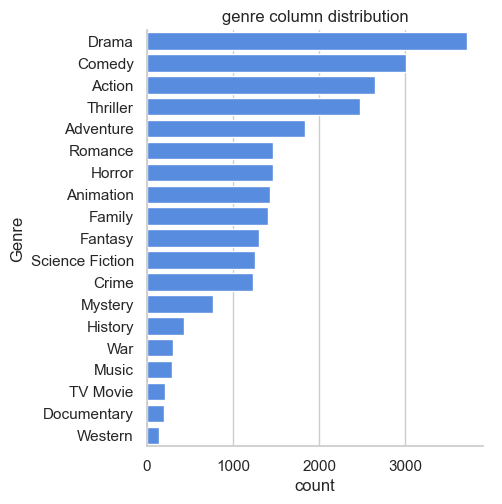

In [12]:
# visualizing genre column
sns.catplot(y = 'Genre', data = df, kind = 'count',
 order = df['Genre'].value_counts().index,
 color = '#4287f5')
plt.title('genre column distribution')
plt.show()

### Vote-Average Distribution

How are movies distributed across the quartile-based vote categories?

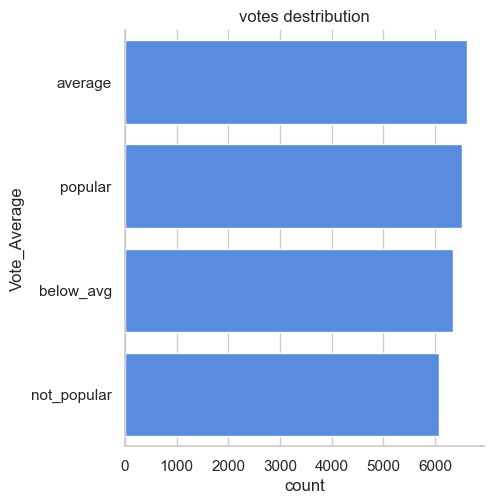

In [13]:
# visualizing vote_average column
sns.catplot(y = 'Vote_Average', data = df, kind = 'count',
 order = df['Vote_Average'].value_counts().index,
 color = '#4287f5')
plt.title('votes destribution')
plt.show() 

### Most Popular Movie

The popularity score is used to identify the movie with the highest recorded popularity in the dataset.

In [14]:
most_popular = df.loc[df["Popularity"].idxmax(), ["Title", "Release_Date", "Popularity", "Vote_Count", "Vote_Average", "Genre"]]
display(most_popular.to_frame("Value"))

,Value
Title,Spider-Man: No Way Home
Release_Date,2021
Popularity,"5,083.95"
Vote_Count,8940
Vote_Average,popular
Genre,Action


### Least Popular Movie

The minimum popularity score is inspected using the same approach.

In [15]:
least_popular = df.loc[df["Popularity"].idxmin(), ["Title", "Release_Date", "Popularity", "Vote_Count", "Vote_Average", "Genre"]]
display(least_popular.to_frame("Value"))

,Value
Title,The United States vs. Billie Holiday
Release_Date,2021
Popularity,13.35
Vote_Count,152
Vote_Average,average
Genre,Music


### Movie Releases Over Time

The release-year distribution shows how the number of movies in the dataset changes across time.

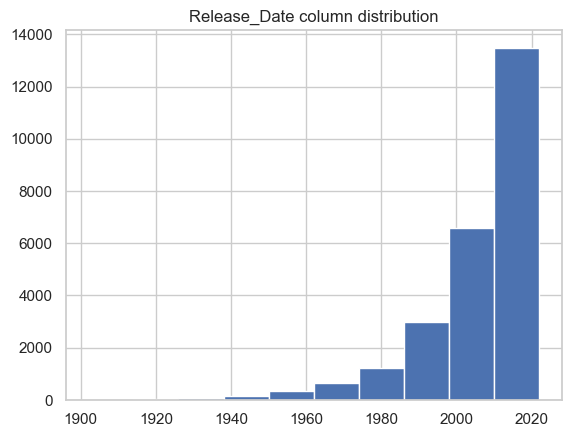

In [16]:
df['Release_Date'].hist()
plt.title('Release_Date column distribution')
plt.show()

## 4. Key Findings

Based on the analysis performed above:

- The dataset initially contains **9,827 movies** across **9 columns**.
- There are **19 distinct genres** after expanding the multi-genre field.
- **Drama** is the most frequently represented genre in the expanded dataset.
- **Spider-Man: No Way Home** has the highest recorded popularity score in the provided data.
- The vote-average distribution is fairly balanced across the four quartile-based categories.
- Release-year analysis helps identify periods with higher representation in the dataset.

> **Note:** Popularity and genre counts are dataset-specific measures. They should not be interpreted as universal rankings of all movies.

## 5. Conclusion

This project demonstrates a complete beginner-to-intermediate **Exploratory Data Analysis (EDA)** workflow using Python. The analysis covers data inspection, cleaning, transformation, categorical feature engineering, multi-value column handling, and visualization.

### Skills Demonstrated
**Python • Pandas • NumPy • Data Cleaning • Feature Engineering • EDA • Matplotlib • Seaborn • Data Visualization**

---

### Possible Next Steps
- Analyze the relationship between **vote count, popularity, and vote average**
- Compare genre performance across different years
- Build an interactive dashboard using **Power BI**
- Develop a recommendation model based on movie attributes
